# Finetuning for Text Classification

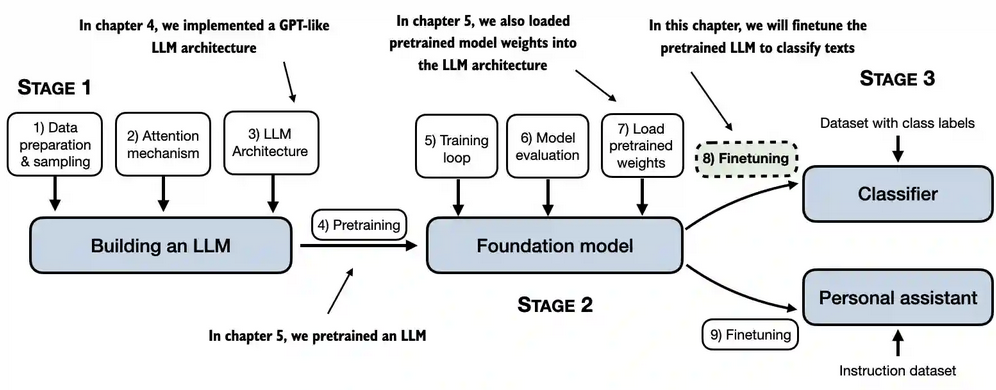

The most common ways to finetune language models are instruction-finetuning and classification finetuning

Instruction-finetuning

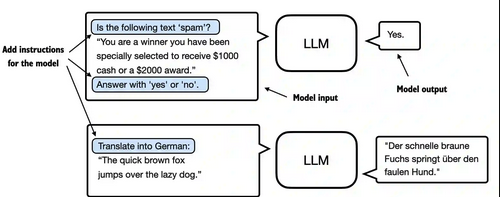

Classification-finetuning

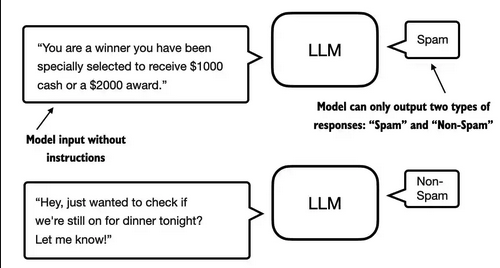

## Lets develop a classification fine tuning example

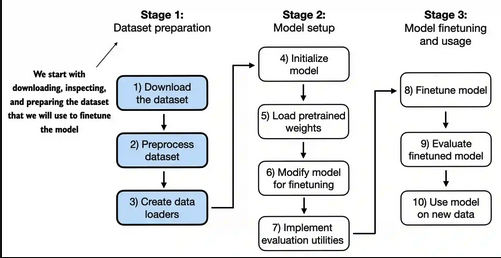

## Step 1&2 : Lets download the dataset and pre process it

In [1]:
import urllib.request
import zipfile
import os
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extracted_path = "sms_spam_collection"
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"

def download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path):
    if data_file_path.exists():
        print(f"{data_file_path} already exists. Skipping download and extraction.")
        return

    # Downloading the file
    with urllib.request.urlopen(url) as response:
        with open(zip_path, "wb") as out_file:
            out_file.write(response.read())

    # Unzipping the file
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extracted_path)

    # Add .tsv file extension
    original_file_path = Path(extracted_path) / "SMSSpamCollection"
    os.rename(original_file_path, data_file_path)
    print(f"File downloaded and saved as {data_file_path}")

try:
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)
except (urllib.error.HTTPError, urllib.error.URLError, TimeoutError) as e:
    print(f"Primary URL failed: {e}. Trying backup URL...")
    url = "https://f001.backblazeb2.com/file/LLMs-from-scratch/sms%2Bspam%2Bcollection.zip"
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path) 



File downloaded and saved as sms_spam_collection/SMSSpamCollection.tsv


In [2]:
import pandas as pd

df = pd.read_csv(data_file_path, sep = "\t" , header = None , names = ["Label" , "Text"])

df

,Label,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [4]:
df['Label'].value_counts()

Label
ham     4825
spam     747
Name: count, dtype: int64

Its an unbalanced dataset. Hence we can undersample the ham class to get equal examples of spam and ham 

In [7]:
def create_balanced_dataset(df):
    
    num_spam = df[df['Label']=='spam'].shape[0]
    
    #randomle sample "ham" instances to match the number of "spam" instances
    
    ham_subset = df[df['Label']=='ham'].sample(num_spam , random_state = 123)
    
    #combine the two 
    balanced_df = pd.concat([ham_subset , df[df['Label'] == 'spam']])
    
    return balanced_df

balanced_df = create_balanced_dataset(df)

balanced_df['Label'].value_counts()
    

Label
ham     747
spam    747
Name: count, dtype: int64

Now lets do label encoding to the targets

In [8]:
balanced_df['Label'] = balanced_df['Label'].map({"ham":0 , "spam":1})

balanced_df['Label'].value_counts()

Label
0    747
1    747
Name: count, dtype: int64

Now divide the dataset into train test validation splits

In [14]:
from sklearn.model_selection import train_test_split

X = balanced_df['Text']
y = balanced_df['Label']

X_train, X_rem, y_train, y_rem = train_test_split(
    X, y, test_size=0.30, random_state=123)

X_test, X_valid, y_test, y_valid = train_test_split(
    X_rem, y_rem, test_size=0.33, random_state=123)

print(X_train.shape)
print(X_test.shape)
print(X_valid.shape)

train_df = pd.DataFrame({'Label': y_train , 'Text': X_train,})
test_df = pd.DataFrame({ 'Label': y_test , 'Text': X_test})
valid_df = pd.DataFrame({ 'Label': y_valid , 'Text': X_valid})



(1045,)
(300,)
(149,)


In [20]:
train_df.to_csv('train.csv', index=None)
test_df.to_csv('test.csv', index=None)
valid_df.to_csv('validation.csv', index=None)

## Step 3: Lets create dataloader

ALl the text messages have different lengths; if we want to combine multiple training examples in a batch, we have to either

    - truncate all messages to the length of the shortest message in the dataset or batch
    - pad all messages to the length of the longest message in the dataset or batch

We choose option 2 and pad all messages to the longest message in the dataset. 

For that, we use <|endoftext|> as a padding token

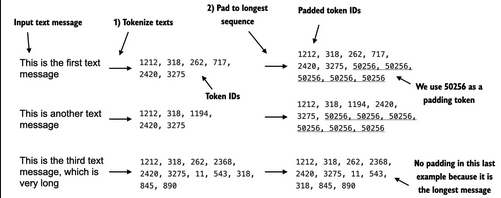

In [57]:
import torch 

from torch.utils.data import Dataset

class SpamDataset(Dataset): 
    
    def __init__(self , csv_file , tokenizer , max_length = None , pad_token_id = 50256):
        
        self.data = pd.read_csv(csv_file)
        
        # tokenize the text 
        
        self.encoded_texts = [
                tokenizer.encode(text) for text in self.data["Text"]
            ]
        
        if max_length is None: 
            self.max_length = self.__longest_encoded_length()
        else:
            self.max_length = max_length
            
            # turncate sequences if they are longer than max_length
            
            self.encoded_texts = [
                encoded_text[:self.max_length]
                for encoded_text in self.encoded_texts
            ]
            
        # pad sequences with pad_token_id of they are less than max_length
        
        self.encoded_texts = [
                encoded_text + [pad_token_id] * (self.max_length - len(encoded_text))
                for encoded_text in self.encoded_texts
            ]
        
        
    def __getitem__(self, index):
        encoded = self.encoded_texts[index]
        label = self.data.iloc[index]["Label"]
        
        return(torch.tensor(encoded,dtype=torch.long) , torch.tensor(label,dtype=torch.long))
     
    def __len__(self):
        return len(self.data)
    
    def __longest_encoded_length(self):
        return (max(len(encoded_text) for encoded_text in self.encoded_texts))
            
            

In [58]:
import tiktoken

tokenizer = tiktoken.get_encoding('gpt2')

train_dataset = SpamDataset(
    csv_file="train.csv",
    max_length=120,
    tokenizer=tokenizer
)

print(train_dataset.max_length)



120


In [59]:
validation_dataset = SpamDataset(
    csv_file="validation.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)

print(validation_dataset.max_length)

120


In [60]:
test_dataset = SpamDataset(
    csv_file="test.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)

print(test_dataset.max_length)

120


Lets create the dataloader for these datasets

In [65]:
from torch.utils.data import DataLoader

num_workers = 0 
batch_size = 8 

torch.manual_seed(123)

train_loader = DataLoader(dataset=train_dataset, 
                          batch_size=batch_size, 
                          shuffle=True, 
                          num_workers=num_workers, 
                          drop_last=True)

validation_loader = DataLoader(dataset=validation_dataset, 
                          batch_size=batch_size, 
                          shuffle=True, 
                          num_workers=num_workers, 
                          drop_last=True)

test_loader = DataLoader(dataset=test_dataset, 
                          batch_size=batch_size, 
                          shuffle=True, 
                          num_workers=num_workers, 
                          drop_last=True)

In [66]:
print("Train Loader")

for input_batch , target_batch in train_loader: 
    pass

print(f'Input batch dimension: {input_batch.shape}')
print(f'Target batch dimension: {target_batch.shape}')

Train Loader
Input batch dimension: torch.Size([8, 120])
Target batch dimension: torch.Size([8])


In [67]:
print(f'{len(train_loader)} count of training batches')
print(f'{len(validation_loader)} count of validation batches')
print(f'{len(test_loader)} count of test batches')


130 count of training batches
18 count of validation batches
37 count of test batches


## Step 4: Initialize the model

In [78]:
import torch.nn as nn 

class MultiHeadAttention(nn.Module):
    
    def __init__(self , d_in , d_out , context_length , dropout , num_heads , qkv_bias = False):
        super().__init__()
        
        assert(d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"
            
        self.d_out = d_out 
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads 
        
        self.W_query = nn.Linear(d_in , d_out , bias = qkv_bias)
        self.W_key = nn.Linear(d_in , d_out , bias = qkv_bias)
        self.W_value = nn.Linear(d_in , d_out , bias = qkv_bias)
        
        self.dropout = nn.Dropout(dropout)
        self.out_proj = nn.Linear(d_out , d_out)
        self.register_buffer(
            "mask" , 
            torch.triu(torch.ones(context_length , context_length), diagonal=1)
        )
        
    def forward(self , x): 
        
        b , num_token , d_in = x.shape
        
        keys = self.W_key(x) # shape = b , num_token , d_out
        values = self.W_value(x)
        queries = self.W_query(x)
        
        # split the above matrices into 4-D Byh adding in num_heads into the dimentions 
        
        keys = keys.view(b , num_token , self.num_heads , self.head_dim )
        values = values.view(b , num_token , self.num_heads , self.head_dim )
        queries = queries.view(b , num_token , self.num_heads , self.head_dim )
        
        # transpose - b , num_token , self.num_heads , self.head_dim ---> b , self.num_heads , num_token , self.head_dim
        
        keys = keys.transpose(1,2)
        values = values.transpose(1,2)
        queries = queries.transpose(1,2)
        
        # Compute scaled dot product attemtion 
        
        atten_score = queries @ keys.transpose(2,3) # b , self.num_heads , num_token , num_token
        
        # Use mask to only look at attention for the tokens seen 
        
        mask_bool = self.mask.bool()[:num_token , :num_token]
        
        # use the mask 
        atten_score.masked_fill_(mask_bool, -torch.inf)
        
        # calculate attention wieghts 
        
        atten_weights = torch.softmax(atten_score/keys.shape[-1] ** 0.5 , dim = -1) # b , self.num_heads , num_token , num_token
        
        atten_weights = self.dropout(atten_weights)
        
        context_vec = atten_weights @ values  # b , self.num_heads , num_token , self.head_dim
        
        context_vec = context_vec.transpose(1,2) # b , num_token  , self.num_heads , self.head_dim
        
        # combine heads 
        context_vec = context_vec.contiguous().view(b , num_token , self.d_out) # b , num_token  , self.d_out
        context_vec = self.out_proj(context_vec)
        
        return context_vec
    
    
class LayerNorm(nn.Module):
    def __init__(self,emb_dim):
        
        super().__init__()
        
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))
        
    def forward(self , x): 
        mean = x.mean(dim = -1 , keepdim = True)
        variance = x.var(dim = -1 , keepdim = True , unbiased = False) # bessles correction using (n-1) instead of n for variance denominator
        
        norm_x = (x-mean) / torch.sqrt(variance + self.eps) # eps is to avoid division by zero error
        
        return self.scale * norm_x + self.shift # Scale and shift and two traininable parameters. 
    
    
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
        ))
        
  
class FeedForward(nn.Module):
    
    def __init__(self , cfg): 
        
        super().__init__()
        self.layers = nn.Sequential(
                nn.Linear(cfg['emb_dim'] , 4 * cfg['emb_dim']),                    # first linear layer (EXPANSION)
                GELU(),                                                     # GELU Activation Layer 
                nn.Linear(4 * cfg['emb_dim'] ,cfg['emb_dim']),          # Second linear layer (CONTRACTION)
            ) 
        
        
    def forward(self , x): 
        return self.layers(x)
    
    
class TransformerBlock(nn.Module): 
    
    def __init__(self , cfg): 
        
        super().__init__()
        
        self.att = MultiHeadAttention(
            d_in = cfg['emb_dim'],
            d_out = cfg['emb_dim'],
            context_length = cfg['context_length'],
            dropout = cfg['dropout'],
            num_heads = cfg['n_heads'],
            qkv_bias = cfg['qkv_bias']  
        )
        
        self.ff = FeedForward(cfg)
        
        self.norm1 = LayerNorm(cfg['emb_dim'])
        
        self.norm2 = LayerNorm(cfg['emb_dim'])
        
        self.dropout_shortcut = nn.Dropout(cfg['dropout'])
        
        
    def forward(self , x): 
        
        # Shortcut connection for the attention block 
        shortcut  = x 
        
        x = self.norm1(x)
        x = self.att(x)
        x = self.dropout_shortcut(x)
        x = x + shortcut
        
        # shortcut connection for feedforward 
        shortcut = x 
        
        x = self.norm2(x)
        x = self.ff(x)
        x = self.dropout_shortcut(x)
        
        x = x + shortcut
        
        return x  
    
class GPTModel(nn.Module): 
    
    def __init__(self , cfg): 
        
        super().__init__()
        
        self.token_emb = nn.Embedding(cfg['vocab_size'] , cfg['emb_dim'])
        self.positional_emb = nn.Embedding(cfg['context_length'] , cfg['emb_dim'])
        
        self.drop_emb = nn.Dropout(cfg['dropout'])
        
        self.transformer_block = nn.Sequential(
            
            *[TransformerBlock(cfg) for _ in range(cfg['n_layers'])]
            
        )
        
        self.final_norm = LayerNorm(cfg['emb_dim'])
        
        self.out_head = nn.Linear(
            cfg['emb_dim'] , cfg['vocab_size'] , bias = False
        )
        
        
    def forward(self , in_indx): 
        
        batch_size , seq_len = in_indx.shape
        
        token_embeddings = self.token_emb(in_indx)
        position_embeddings = self.positional_emb(torch.arange(seq_len, device = in_indx.device))
        
        x = token_embeddings + position_embeddings
        x= self.drop_emb(x)
        
        x = self.transformer_block(x)
        x = self.final_norm(x)
        
        logits = self.out_head(x)
        
        return logits
    
    
import numpy as np

def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))

def load_weights_into_gpt(gpt, params):
    gpt.positional_emb.weight = assign(gpt.positional_emb.weight, params['wpe'])
    gpt.token_emb.weight = assign(gpt.token_emb.weight, params['wte'])
    
    for b in range(len(params["blocks"])):
        q_w, k_w, v_w = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.transformer_block[b].att.W_query.weight = assign(
            gpt.transformer_block[b].att.W_query.weight, q_w.T)
        gpt.transformer_block[b].att.W_key.weight = assign(
            gpt.transformer_block[b].att.W_key.weight, k_w.T)
        gpt.transformer_block[b].att.W_value.weight = assign(
            gpt.transformer_block[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.transformer_block[b].att.W_query.bias = assign(
            gpt.transformer_block[b].att.W_query.bias, q_b)
        gpt.transformer_block[b].att.W_key.bias = assign(
            gpt.transformer_block[b].att.W_key.bias, k_b)
        gpt.transformer_block[b].att.W_value.bias = assign(
            gpt.transformer_block[b].att.W_value.bias, v_b)

        gpt.transformer_block[b].att.out_proj.weight = assign(
            gpt.transformer_block[b].att.out_proj.weight, 
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.transformer_block[b].att.out_proj.bias = assign(
            gpt.transformer_block[b].att.out_proj.bias, 
            params["blocks"][b]["attn"]["c_proj"]["b"])

        gpt.transformer_block[b].ff.layers[0].weight = assign(
            gpt.transformer_block[b].ff.layers[0].weight, 
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.transformer_block[b].ff.layers[0].bias = assign(
            gpt.transformer_block[b].ff.layers[0].bias, 
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.transformer_block[b].ff.layers[2].weight = assign(
            gpt.transformer_block[b].ff.layers[2].weight, 
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.transformer_block[b].ff.layers[2].bias = assign(
            gpt.transformer_block[b].ff.layers[2].bias, 
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        gpt.transformer_block[b].norm1.scale = assign(
            gpt.transformer_block[b].norm1.scale, 
            params["blocks"][b]["ln_1"]["g"])
        gpt.transformer_block[b].norm1.shift = assign(
            gpt.transformer_block[b].norm1.shift, 
            params["blocks"][b]["ln_1"]["b"])
        gpt.transformer_block[b].norm2.scale = assign(
            gpt.transformer_block[b].norm2.scale, 
            params["blocks"][b]["ln_2"]["g"])
        gpt.transformer_block[b].norm2.shift = assign(
            gpt.transformer_block[b].norm2.shift, 
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])    

In [75]:
CHOOSE_MODEL = "gpt2-small (124M)"
INPUT_PROMPT = "Every effort moves"

BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "dropout": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

assert train_dataset.max_length <= BASE_CONFIG["context_length"], (
    f"Dataset length {train_dataset.max_length} exceeds model's context "
    f"length {BASE_CONFIG['context_length']}. Reinitialize data sets with "
    f"`max_length={BASE_CONFIG['context_length']}`"
)

In [79]:
import sys
sys.path.append(os.path.abspath('../../training_llms/code'))

from gpt_download3 import download_and_load_gpt2

In [80]:

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(model_size=model_size, models_dir="../../training_llms/code/gpt2")

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();



/Users/sprabhu/.local/share/virtualenvs/GitHub-sKygbMQR/lib/python3.10/site-packages/urllib3/connectionpool.py:1045: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(
/Users/sprabhu/.local/share/virtualenvs/GitHub-sKygbMQR/lib/python3.10/site-packages/urllib3/connectionpool.py:1045: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(


File already exists and is up-to-date: ../../training_llms/code/gpt2/124M/checkpoint
File already exists and is up-to-date: ../../training_llms/code/gpt2/124M/encoder.json


/Users/sprabhu/.local/share/virtualenvs/GitHub-sKygbMQR/lib/python3.10/site-packages/urllib3/connectionpool.py:1045: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(
/Users/sprabhu/.local/share/virtualenvs/GitHub-sKygbMQR/lib/python3.10/site-packages/urllib3/connectionpool.py:1045: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(


File already exists and is up-to-date: ../../training_llms/code/gpt2/124M/hparams.json
File already exists and is up-to-date: ../../training_llms/code/gpt2/124M/model.ckpt.data-00000-of-00001


/Users/sprabhu/.local/share/virtualenvs/GitHub-sKygbMQR/lib/python3.10/site-packages/urllib3/connectionpool.py:1045: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(
/Users/sprabhu/.local/share/virtualenvs/GitHub-sKygbMQR/lib/python3.10/site-packages/urllib3/connectionpool.py:1045: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(


File already exists and is up-to-date: ../../training_llms/code/gpt2/124M/model.ckpt.index
File already exists and is up-to-date: ../../training_llms/code/gpt2/124M/model.ckpt.meta


/Users/sprabhu/.local/share/virtualenvs/GitHub-sKygbMQR/lib/python3.10/site-packages/urllib3/connectionpool.py:1045: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(


File already exists and is up-to-date: ../../training_llms/code/gpt2/124M/vocab.bpe


In [87]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        #Filter logits with top_k sampling
        if top_k is not None:
            # Keep only top_k values
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(logits < min_val, torch.tensor(float("-inf")).to(logits.device), logits)

        # Apply temperature scaling
        if temperature > 0.0:
            logits = logits / temperature

            # Apply softmax to get probabilities
            probs = torch.softmax(logits, dim=-1)  # (batch_size, context_len)

            # Sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1)  # (batch_size, 1)

        # Otherwise same as before: get idx of the vocab entry with the highest logits value
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)  # (batch_size, 1)

        if idx_next == eos_id:  # Stop generating early if end-of-sequence token is encountered and eos_id is specified
            break

        # append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch_size, num_tokens+1)

    return idx
# Alternatively:
# from llms_from_scratch.ch05 import (
#    generate_text_simple,
#    text_to_token_ids,
#    token_ids_to_text
# )

def text_to_token_ids(text , tokenizer):
    
    encoded = tokenizer.encode(text , allowed_special = {'<|endoftext|>'})
    
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # Add batch dimension
    
    return encoded_tensor

def token_ids_to_text(token_ids , tokenizer):
    decoded = tokenizer.decode(token_ids.squeeze(0).tolist())
    
    return decoded


text_1 = "Every effort moves you"

token_ids = generate(
    model=model,
    idx=text_to_token_ids(text_1, tokenizer),
    max_new_tokens=50,
    context_size=BASE_CONFIG["context_length"], 
    temperature=2,top_k = 3
    
)

print(token_ids_to_text(token_ids, tokenizer))



Every effort moves you along, and the best thing is to keep your heart on track. If you're feeling overwhelmed or stressed, it can be difficult to keep up with your goals and goals are not always going in sync with your goals, so it's better not to


In [88]:
text_2 = (
    "Is the following text 'spam'? Answer with 'yes' or 'no':"
    " 'You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award.'"
)

token_ids = generate(
    model=model,
    idx=text_to_token_ids(text_2, tokenizer),
    max_new_tokens=23,
    context_size=BASE_CONFIG["context_length"]
)

print(token_ids_to_text(token_ids, tokenizer))

Is the following text 'spam'? Answer with 'yes' or 'no': 'You are a winner you have been specially selected to receive $1000 cash or a $2000 award.'

The following text 'spam'? Answer with 'yes' or 'no': 'You are a winner


The model fails at answering (as the model is just pretrained and not instruction fine tuned)

## Step 5 & 6: Modify the model for classification (add a classification head)

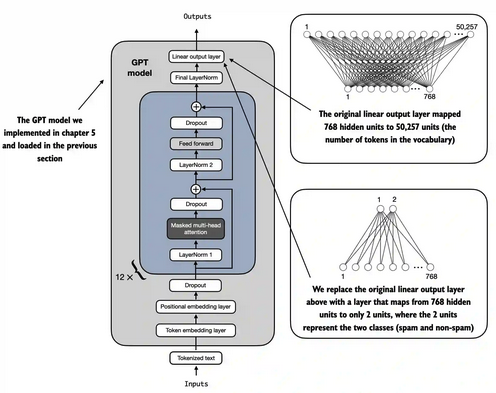

we first freeze the model, meaning that we make all layers non-trainable

In [89]:
for param in model.parameters():
    param.requires_grad = False

In [90]:
torch.manual_seed(123)
num_classes = 2

model.out_head = torch.nn.Linear(in_features=BASE_CONFIG["emb_dim"] , out_features=num_classes)

Along with the final output head, we also want to retrain the weights for the final transformer block and the final layer normalization module

In [92]:
for param in model.transformer_block[-1].parameters():
    param.requires_grad = True
    
for param in model.final_norm.parameters():
    param.requires_grad = True   

We can play around with what to train and what not to train to get the most performance

In [95]:
input = torch.tensor(tokenizer.encode('Do you have time?')).unsqueeze(0)

print(f'Input: \n {input} ')

print(f'Input Dimension: \n {input.shape} ')


with torch.no_grad():
    output = model(input)

print(f'Output: \n {output} ')

print(f'Output Dimension: \n {output.shape} ')    

Input: 
 tensor([[5211,  345,  423,  640,   30]]) 
Input Dimension: 
 torch.Size([1, 5]) 
Output: 
 tensor([[[-1.5854,  0.9904],
         [-3.7235,  7.4548],
         [-2.2661,  6.6049],
         [-3.5983,  3.9902],
         [-5.2433,  6.3857]]]) 
Output Dimension: 
 torch.Size([1, 5, 2]) 


We are only interested in the last row output [-5.2433,  6.3857]

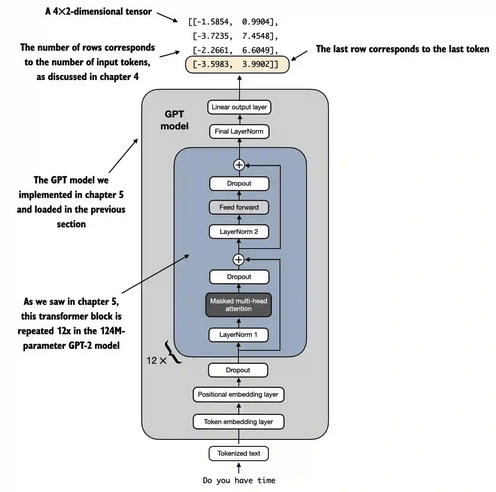

In [96]:
print("Last output token:", output[:, -1, :])

Last output token: tensor([[-5.2433,  6.3857]])


## Step 7: Implement the evaluation utilities

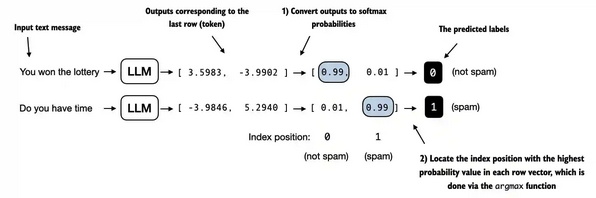

In [97]:
probas = torch.softmax(output[:, -1, :], dim=-1)
label = torch.argmax(probas)
print("Class label:", label.item())

Class label: 1


softmax is option as the largest prob is the class

In [98]:
logits = output[:, -1, :]
label = torch.argmax(logits)
print("Class label:", label.item())

Class label: 1


Lets calculate the class accuracy

In [108]:
def calc_accuracy_loader(data_loader , model , device , num_batches = None):
    
    model.eval()
    
    correct_preds , num_examples = 0 , 0 
    
    if num_batches is None: 
        num_batches = len(data_loader)
        
    else:
        num_batches = min(num_batches , len(data_loader))
        
    for i , (input_batch , target_batch) in enumerate(data_loader): 
        
        if i < num_batches: 
            input_batch , target_batch = input_batch.to(device) , target_batch.to(device)
            
            with torch.no_grad():
                output = model(input_batch)[:,-1,:]
                
            predicted_label = torch.argmax(output , dim = -1)
            
            num_examples += predicted_label.shape[0]
            correct_preds += (predicted_label == target_batch).sum().item()
        else:
            break 
        
    return(correct_preds / num_examples)

In [109]:
device = torch.device("mps")

model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes

torch.manual_seed(123) # For reproducibility due to the shuffling in the training data loader

train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=10)
val_accuracy = calc_accuracy_loader(validation_loader, model, device, num_batches=10)
test_accuracy = calc_accuracy_loader(test_loader, model, device, num_batches=10)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 53.75%
Validation accuracy: 43.75%
Test accuracy: 55.00%


since the model is untrained - the accuracy isnt great 

In [104]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)[:, -1, :]
    loss = torch.nn.functional.cross_entropy(logits, target_batch)
    return loss

In [105]:
def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

In [106]:
with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
    val_loss = calc_loss_loader(validation_loader, model, device, num_batches=5)
    test_loss = calc_loss_loader(test_loader, model, device, num_batches=5)

print(f"Training loss: {train_loss:.3f}")
print(f"Validation loss: {val_loss:.3f}")
print(f"Test loss: {test_loss:.3f}")


Training loss: 2.434
Validation loss: 2.536
Test loss: 1.932


## Step 8: Fine tuning the model 

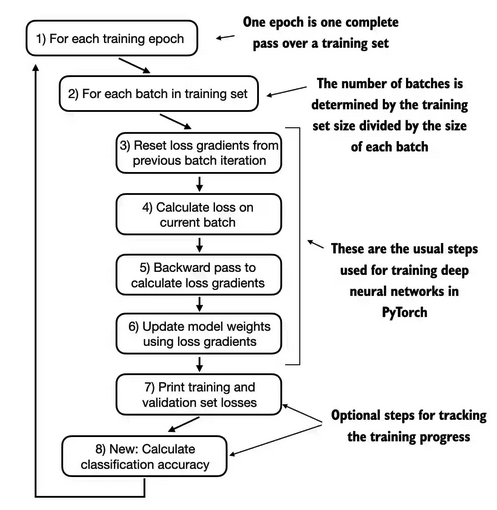

In [ ]:
def train_classifier_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                            eval_freq, eval_iter):
    # Initialize lists to track losses and examples seen
    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    examples_seen, global_step = 0, -1

    # Main training loop
    for epoch in range(num_epochs):
        model.train()  # Set model to training modev

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() # Reset loss gradients from previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() # Calculate loss gradients
            optimizer.step() # Update model weights using loss gradients
            examples_seen += input_batch.shape[0] # New: track examples instead of tokens
            global_step += 1

            # Optional evaluation step
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # Calculate accuracy after each epoch
        train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=eval_iter)
        val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=eval_iter)
        print(f"Training accuracy: {train_accuracy*100:.2f}% | ", end="")
        print(f"Validation accuracy: {val_accuracy*100:.2f}%")
        train_accs.append(train_accuracy)
        val_accs.append(val_accuracy)

    return train_losses, val_losses, train_accs, val_accs, examples_seen

In [111]:
def evaluate_model(model, train_loader, validation_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(validation_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss

In [112]:
import time
start_time = time.time()
torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.1)

num_epochs = 5
train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
    model, train_loader, validation_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=50, eval_iter=5,
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 2.717, Val loss 2.275
Ep 1 (Step 000050): Train loss 0.667, Val loss 0.857
Ep 1 (Step 000100): Train loss 0.517, Val loss 0.741
Training accuracy: 67.50% | Validation accuracy: 62.50%
Ep 2 (Step 000150): Train loss 0.531, Val loss 0.544
Ep 2 (Step 000200): Train loss 0.507, Val loss 0.454
Ep 2 (Step 000250): Train loss 0.216, Val loss 0.601
Training accuracy: 80.00% | Validation accuracy: 85.00%
Ep 3 (Step 000300): Train loss 0.325, Val loss 0.426
Ep 3 (Step 000350): Train loss 0.181, Val loss 0.502
Training accuracy: 95.00% | Validation accuracy: 92.50%
Ep 4 (Step 000400): Train loss 0.083, Val loss 0.217
Ep 4 (Step 000450): Train loss 0.298, Val loss 0.220
Ep 4 (Step 000500): Train loss 0.098, Val loss 0.513
Training accuracy: 95.00% | Validation accuracy: 92.50%
Ep 5 (Step 000550): Train loss 0.039, Val loss 0.454
Ep 5 (Step 000600): Train loss 0.015, Val loss 0.278
Training accuracy: 97.50% | Validation accuracy: 95.00%
Training completed in 1.33 minu

In [113]:
import matplotlib.pyplot as plt
def plot_values(epochs_seen, examples_seen, train_values, val_values, label="loss"):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_values, label=f"Training {label}")
    ax1.plot(epochs_seen, val_values, linestyle="-.", label=f"Validation {label}")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel(label.capitalize())
    ax1.legend()

    # Create a second x-axis for examples seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(examples_seen, train_values, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Examples seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig(f"{label}-plot.pdf")
    plt.show()



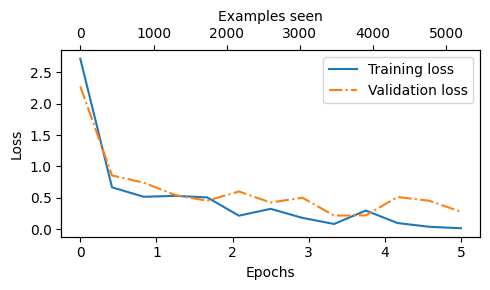

In [114]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))

plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses)

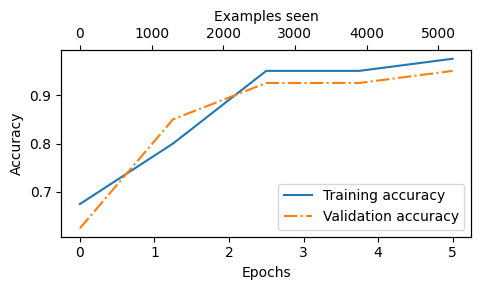

In [115]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_accs))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_accs))
plot_values(epochs_tensor, examples_seen_tensor, train_accs, val_accs, label="accuracy")

In [116]:
train_accuracy = calc_accuracy_loader(train_loader, model, device)
val_accuracy = calc_accuracy_loader(validation_loader, model, device)
test_accuracy = calc_accuracy_loader(test_loader, model, device)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 96.83%
Validation accuracy: 92.36%
Test accuracy: 96.28%


We increased the accuracy from ~50 % to ~95%

## Step 9: Using LLM as Spam classifier

In [117]:
def classify_review(text, model, tokenizer, device, max_length=None, pad_token_id=50256):
    model.eval()
    input_ids = tokenizer.encode(text)
    supported_context_length = model.positional_emb.weight.shape[0]

    # Truncate sequences if they too long
    input_ids = input_ids[:min(max_length, supported_context_length)]
    assert max_length is not None, (
        "max_length must be specified. If you want to use the full model context, "
        "pass max_length=model.positional_emb.weight.shape[0]."
    )
    assert max_length <= supported_context_length, (
        f"max_length ({max_length}) exceeds model's supported context length ({supported_context_length})."
    )    
    # Pad sequences to the longest sequence
    input_ids += [pad_token_id] * (max_length - len(input_ids))
    input_tensor = torch.tensor(input_ids, device=device).unsqueeze(0) # add batch dimension

    # Model inference
    with torch.no_grad():
        logits = model(input_tensor)[:, -1, :]  # Logits of the last output token
    predicted_label = torch.argmax(logits, dim=-1).item()

    # Return the classified result
    return "spam" if predicted_label == 1 else "not spam"



In [126]:
pd.set_option('display.max_rows', 20)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
df[df['Label']=='spam']['Text']

2            Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
5                    FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
8          WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
9             Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030
11                              SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info
                                                                                      ...                                                                  

In [127]:
text_1 = (
    "FreeMsg Hey there darling it's"
    " been 3 week's now and no word back!"
    "I'd like some fun you up for it still? "
    " Tb ok! XxX std chgs to send, £1.50 to rcv"
)

print(classify_review(
    text_1, model, tokenizer, device, max_length=train_dataset.max_length
))


spam


In [128]:
pd.set_option('display.max_rows', 20)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
df[df['Label']=='ham']['Text']

0                     Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
1                                                                                                       Ok lar... Joking wif u oni...
3                                                                                   U dun say so early hor... U c already then say...
4                                                                       Nah I don't think he goes to usf, he lives around here though
6                                                       Even my brother is not like to speak with me. They treat me like aids patent.
                                                                    ...                                                              
5565                                                                                                                     Huh y lei...
5568                                                          

In [129]:
text_2 = (
    "Rofl. Its true to its name"
)

print(classify_review(
    text_2, model, tokenizer, device, max_length=train_dataset.max_length
))

not spam
